# Methods and Parameters for Overlap Tracking

While the default linking method (`tobac.linking_trackpy`) assigns the detected features in each timestep to trajectories based only on their point-like position, **overlap tracking** (`tobac.tracking.linking_overlap`) uses the **spatial extent of the detected features**: features of consecutive timesteps are linked based on the overlap of their labeled masks. This enables an analysis of their time evolution even when features move fast, merge, or cross each other. We will cover the topics:

- [Understanding the Overlap Tracking Output](#Understanding-the-Overlap-Tracking-Output)
- [How the Overlap Matching Works](#How-the-Overlap-Matching-Works)
- [Minimum Overlap](#Minimum-Overlap)
- [Predicting the Feature Positions](#Predicting-the-Feature-Positions)
- [Gappy Tracks](#Gappy-Tracks)
- [Timescale of the Tracks](#Timescale-of-the-Tracks)
- [Periodic Boundary Conditions](#Periodic-Boundary-Conditions)
- [Tracking in 3D](#Tracking-in-3D)
- [Other Parameters](#Other-Parameters)

We start by loading the usual libraries:

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

%matplotlib inline

import seaborn as sns

sns.set_context("talk")


import warnings

warnings.filterwarnings("ignore")

In [3]:
import tobac
import tobac.testing

## Understanding the Overlap Tracking Output

Since it has a time dimension, the sample data from the testing utilities is also suitable for a demonstration of this step. The chosen method creates 2-dimensional sample data with 3 moving blobs at the same time. So, our expectation is to obtain 3 tracks.

Unlike `linking_trackpy`, overlap tracking requires a **labeled mask** of the features in addition to the features dataframe: each grid cell belonging to a feature is labeled with the feature's `feature` ID. Such a mask can be obtained from segmentation, or directly from feature detection with `return_labels=True`:

At first, loading in the data and performing the usual feature detection is required:

In [4]:
%%capture

data = tobac.testing.make_sample_data_2D_3blobs(data_type="xarray")
dxy, dt = tobac.utils.get_spacings(data)
labels, features = tobac.feature_detection_multithreshold(
    data, dxy, threshold=5, position_threshold="weighted_abs", return_labels=True
)

Now the linking via overlap tracking can be performed by passing both the features and the labeled mask:

In [5]:
tracks = tobac.tracking.linking_overlap(features, labels)

In [6]:
np.unique(tracks.cell)

array([1, 2, 3])

The track dataset contains two new variables, *cell* and *time_cell*. The first assigns the features to one of the found trajectories by an integer and the second specifies how long the feature has been present already in the data. Features that are not linked to any track are marked with -1 (the `cell_number_unassigned` value):

In [7]:
tracks[["cell", "time_cell"]][:20]

,cell,time_cell
0,1,0 days 00:00:00
1,1,0 days 00:01:00
2,1,0 days 00:02:00
3,1,0 days 00:03:00
4,1,0 days 00:04:00
5,1,0 days 00:05:00
6,1,0 days 00:06:00
7,1,0 days 00:07:00
8,1,0 days 00:08:00
9,1,0 days 00:09:00


Since we know that this dataset contains 3 features, we can visualize the found tracks with masks created from the *cell* variable:

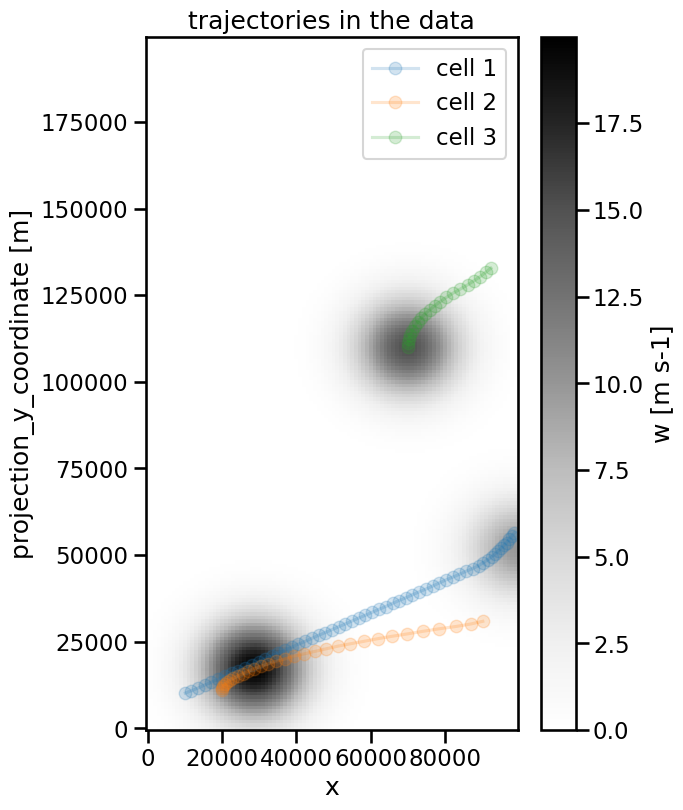

In [8]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6, 9))

data.isel(time=50).plot(ax=ax, x="x", y="y", cmap="Greys")

for i, cell_track in tracks.groupby("cell"):
    if i != -1:
        cell_track.plot(
            x="x",
            y="y",
            ax=ax,
            marker="o",
            alpha=0.2,
            label="cell {0}".format(int(i)),
        )

ax.set_title("trajectories in the data")
plt.legend()

## How the Overlap Matching Works

For each pair of consecutive timesteps, `linking_overlap` computes the overlap between the mask of every feature in the current timestep and the masks of all features in the next timestep. If a feature overlaps with several features in the next timestep (or vice versa), the ambiguity is resolved by choosing the **one-to-one assignment that maximises the total overlap area** (a maximum-weight bipartite matching). Features that cannot be matched end their track at the current timestep, and unmatched features in the next timestep start a new track.

The figure below shows the labeled feature masks at two consecutive timesteps and their overlap (in red):

Text(0.5, 1.0, 'feature masks at two consecutive timesteps and their overlap')

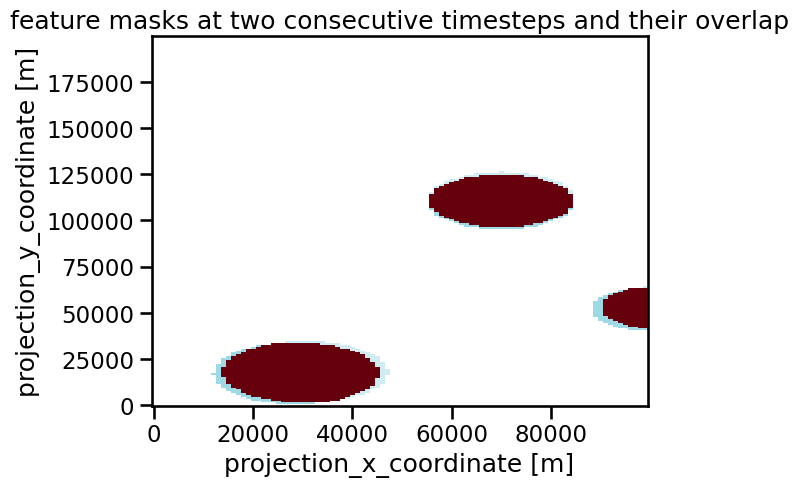

In [9]:
fig, ax = plt.subplots()
labels.where(labels != 0)[50].plot(ax=ax, add_colorbar=False, vmin=0, vmax=3, cmap="tab20")
labels.where(labels != 0)[51].plot(ax=ax, add_colorbar=False, vmin=0, vmax=3, cmap="tab20", alpha=0.5)
labels[50].where((labels[50] != 0) & (labels[51] != 0)).plot(ax=ax, add_colorbar=False, vmin=0, vmax=1, cmap="Reds")

ax.set_title("feature masks at two consecutive timesteps and their overlap")

## Minimum Overlap

Two parameters control what counts as a valid overlap between a feature in one timestep and a feature in the next:

- `minimum_overlap`: the minimum number of overlapping grid cells (pixels in 2D, voxels in 3D)
- `minimum_relative_overlap`: the minimum *fraction* of overlap, computed as the number of overlapping grid cells divided by the size of the *smaller* of the two features (between 0 and 1)

With the default values (`minimum_overlap=1`, `minimum_relative_overlap=0`), any shared grid cell leads to a link. Increasing the thresholds makes the linking stricter: features that only partially overlap are no longer linked, and start/end separate tracks instead. Requiring 90% relative overlap already results in many short tracks and unassigned features (-1) in the 3-blob test data:

In [10]:
tracks_strict = tobac.tracking.linking_overlap(features, labels, minimum_relative_overlap=0.9)
np.unique(tracks_strict.cell)

array([-1,  1,  2,  3,  4,  5,  6,  7,  8])

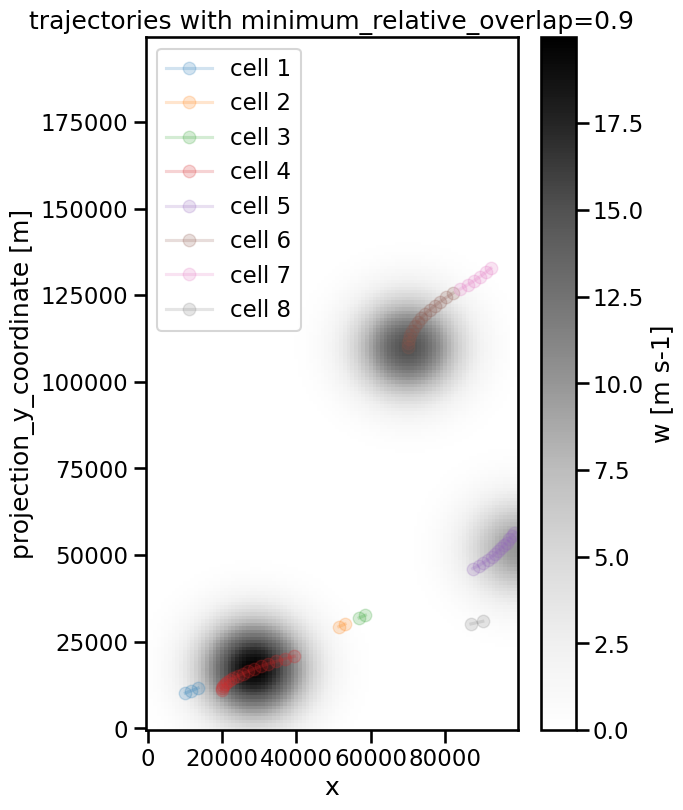

In [11]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6, 9))

data.isel(time=50).plot(ax=ax, x="x", y="y", cmap="Greys")

for i, cell_track in tracks_strict.groupby("cell"):
    if i != -1:
        cell_track.plot(
            x="x",
            y="y",
            ax=ax,
            marker="o",
            alpha=0.2,
            label="cell {0}".format(int(i)),
        )

ax.set_title("trajectories with minimum_relative_overlap=0.9")
plt.legend()

`minimum_overlap` sets an absolute lower bound on the number of overlapping grid cells instead. For the 3-blob test data, requiring 100 overlapping pixels already prevents some of the links:

In [12]:
tracks_min_overlap = tobac.tracking.linking_overlap(features, labels, minimum_overlap=100)
np.unique(tracks_min_overlap.cell)

array([-1,  1,  2,  3])

## Predicting the Feature Positions

So far, the overlap was computed between the features at their detected positions. For fast-moving features it can help to first **translate** each feature from the current to the next timestep, so that the overlap is computed around the *predicted* position of the feature. This is controlled by the `translate_method` parameter:

- `"constant"`: translate every feature by `velocity_constant` times the time difference between the timesteps
- `"drift"`: translate all features by the *mean* velocity of the tracked features times the time difference (uniform background drift)
- `"predict"`: translate each feature by its *own* tracked velocity times the time difference
- `None` (default): no translation

`velocity_constant` is given in grid cells per second, either as a single number or as an array with one value per dimension. When `translate_method="predict"`, features without a track history (e.g. newly detected ones) get their velocity filled according to `velocity_method`: `"constant"` (use `velocity_constant`), `"mean"` (mean of the tracked velocities) or `"nearest"` (velocity of the nearest tracked feature).

We demonstrate this on a 3D dataset with two crossing blobs. Here the segmentation mask is used as the mask input, showing that `linking_overlap` also works with the output of segmentation:

In [13]:
%%capture

data_cross = tobac.testing.make_sample_data_3D_2crossing_blobs_xarray()
dxy, dt = 1000, 120
features_cross = tobac.feature_detection_multithreshold(
    data_cross, dxy, threshold=8, position_threshold="weighted_abs"
)
labels_cross, features_cross = tobac.segmentation.segmentation(
    features_cross, data_cross, dxy, threshold=8
)

With the default settings (no translation), one of the two tracks ends when the blobs cross and a new track is started, so we obtain three cells:

In [14]:
tracks_cross = tobac.tracking.linking_overlap(features_cross, labels_cross)
np.unique(tracks_cross.cell)

array([1, 2, 3])

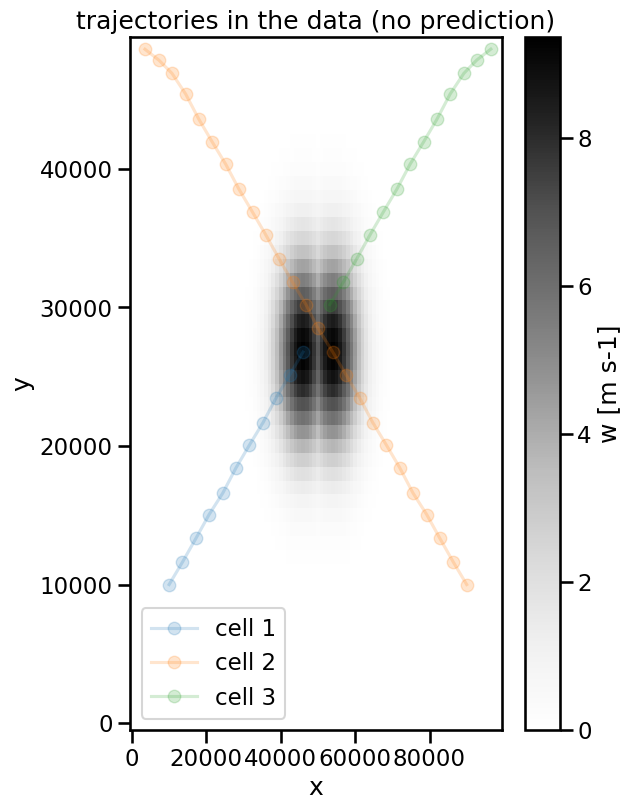

In [15]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6, 9))

data_cross.isel(time=10, z=25).plot(ax=ax, x="x", y="y", cmap="Greys")

for i, cell_track in tracks_cross.groupby("cell"):
    if i != -1:
        cell_track.plot(
            x="x",
            y="y",
            ax=ax,
            marker="o",
            alpha=0.2,
            label="cell {0}".format(int(i)),
        )

ax.set_title("trajectories in the data (no prediction)")
plt.legend()

With `memory=1`, a track is kept alive for one timestep without a match, so both blobs are tracked continuously - but the tracks do not cross:

In [16]:
tracks_cross_mem = tobac.tracking.linking_overlap(features_cross, labels_cross, memory=1)
np.unique(tracks_cross_mem.cell)

array([1, 2])

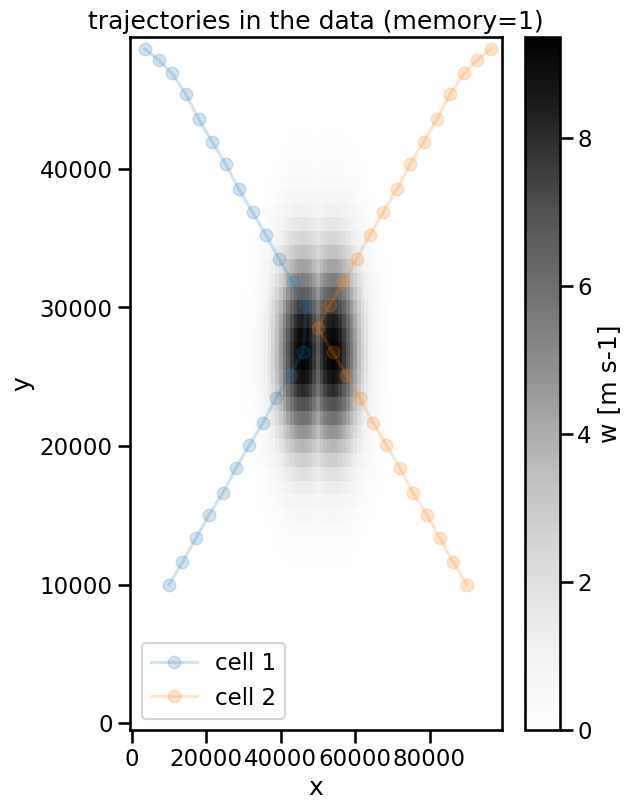

In [17]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6, 9))

data_cross.isel(time=10, z=25).plot(ax=ax, x="x", y="y", cmap="Greys")

for i, cell_track in tracks_cross_mem.groupby("cell"):
    if i != -1:
        cell_track.plot(
            x="x",
            y="y",
            ax=ax,
            marker="o",
            alpha=0.2,
            label="cell {0}".format(int(i)),
        )

ax.set_title("trajectories in the data (memory=1)")
plt.legend()

With `memory=1` **and** `translate_method="predict"`, each blob is translated along its tracked velocity before the overlap is computed. The overlap is then computed at the predicted positions, and the two tracks cross (note how the cell numbers of the first two features are swapped at the last timesteps):

In [18]:
tracks_cross_pred = tobac.tracking.linking_overlap(
    features_cross, labels_cross, memory=1, translate_method="predict", velocity_method="nearest"
)
np.unique(tracks_cross_pred.cell)

array([1, 2])

In [19]:
tracks_cross_pred.cell.iloc[[0, 1, -2, -1]]

0     1
1     2
47    2
48    1
Name: cell, dtype: int64

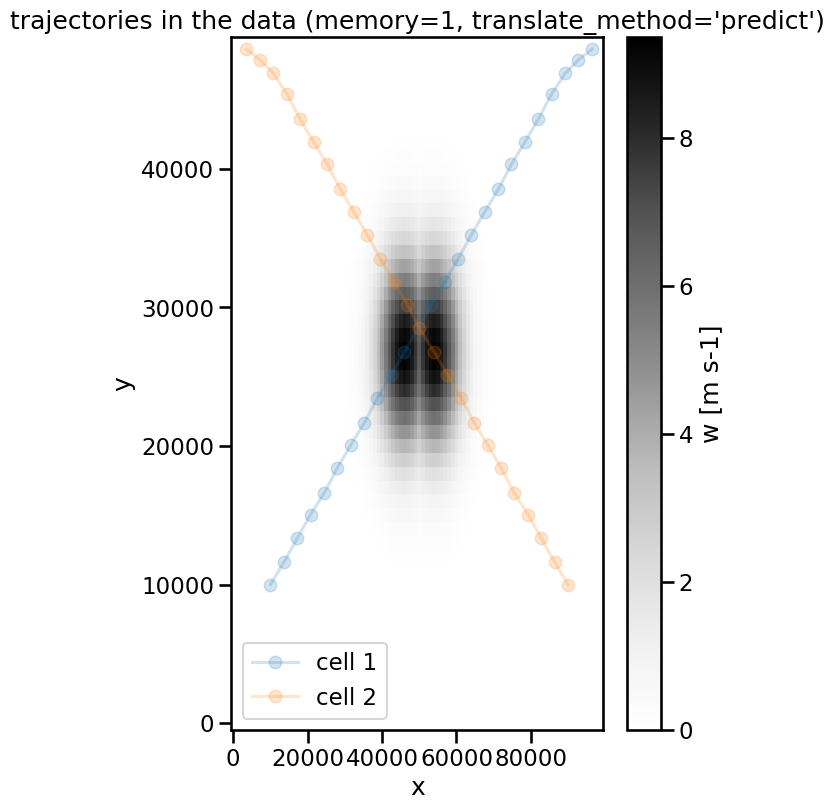

In [20]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6, 9))

data_cross.isel(time=10, z=25).plot(ax=ax, x="x", y="y", cmap="Greys")

for i, cell_track in tracks_cross_pred.groupby("cell"):
    if i != -1:
        cell_track.plot(
            x="x",
            y="y",
            ax=ax,
            marker="o",
            alpha=0.2,
            label="cell {0}".format(int(i)),
        )

ax.set_title("trajectories in the data (memory=1, translate_method='predict')")
plt.legend()

On the 3-blob test data, all choices of `velocity_method` for the predictive linking still recover the 3 tracks:

In [21]:
for velocity_method in ["constant", "mean", "nearest"]:
    tracks_vm = tobac.tracking.linking_overlap(
        features,
        labels,
        minimum_relative_overlap=0.5,
        translate_method="predict",
        velocity_method=velocity_method,
        velocity_constant=0,
    )
    print(velocity_method, np.unique(tracks_vm.cell).tolist())

constant [1, 2, 3]
mean [1, 2, 3]
nearest [1, 2, 3]


## Gappy Tracks

If the data is noisy, an object may disappear for a few frames and then reappear. Such features can still be linked by setting the `memory` parameter with an integer. This defines the number of timeframes a feature can vanish and still get tracked as one cell. We demonstrate this on a simple dataset with only one feature. To simulate a gap in the data we set 5 timeframes to 0:

In [22]:
%%capture

data_gap = tobac.testing.make_simple_sample_data_2D(data_type="xarray")
dxy, dt = tobac.utils.get_spacings(data_gap)
data_gap[30:35] = data_gap[30] * 0
labels_gap, features_gap = tobac.feature_detection_multithreshold(
    data_gap, dxy, threshold=7.5, position_threshold="weighted_abs", return_labels=True
)

If we apply feature detection and overlap tracking to this modified dataset, we get two cells, because the feature after the gap does not overlap with the one before the gap:

In [23]:
tracks_gap = tobac.tracking.linking_overlap(features_gap, labels_gap)
np.unique(tracks_gap.cell)

array([1, 2])

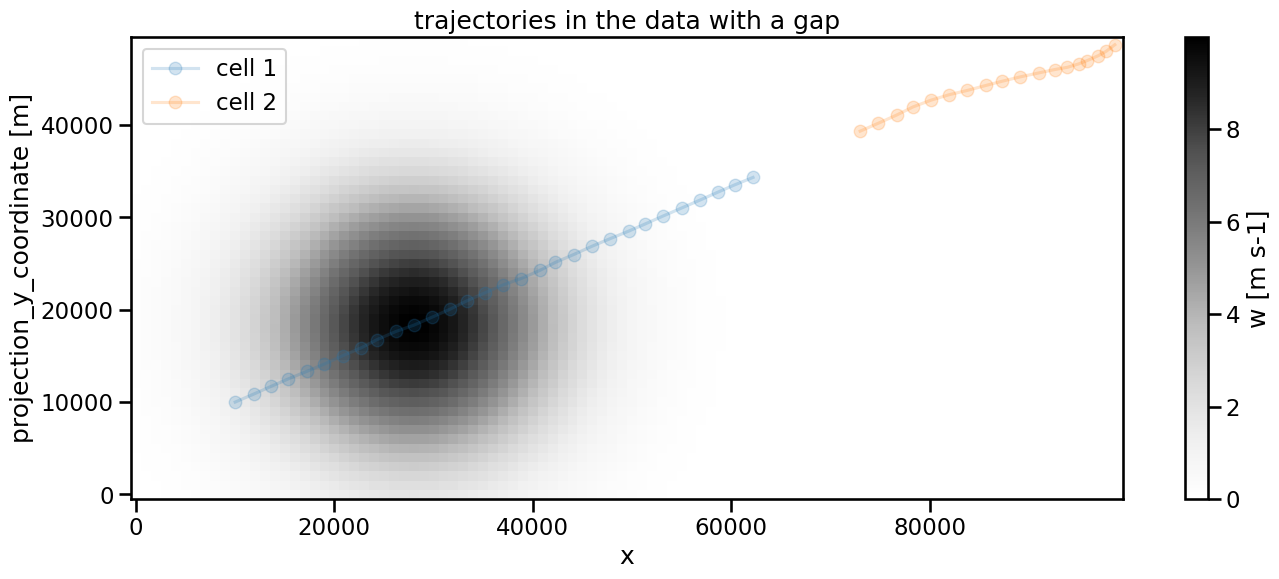

In [24]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(16, 6))

data_gap.isel(time=10).plot(ax=ax, x="x", y="y", cmap="Greys")

for i, cell_track in tracks_gap.groupby("cell"):
    if i != -1:
        cell_track.plot(
            x="x",
            y="y",
            ax=ax,
            marker="o",
            alpha=0.2,
            label="cell {0}".format(int(i)),
        )

ax.set_title("trajectories in the data with a gap")
plt.legend()

We can avoid this by setting `memory` to a sufficiently high number. 5 is of course sufficient in our case as the situation is artificially created, but with real data this would require some fine tuning:

In [25]:
tracks_gap_mem = tobac.tracking.linking_overlap(features_gap, labels_gap, memory=5)
np.unique(tracks_gap_mem.cell)

array([1])

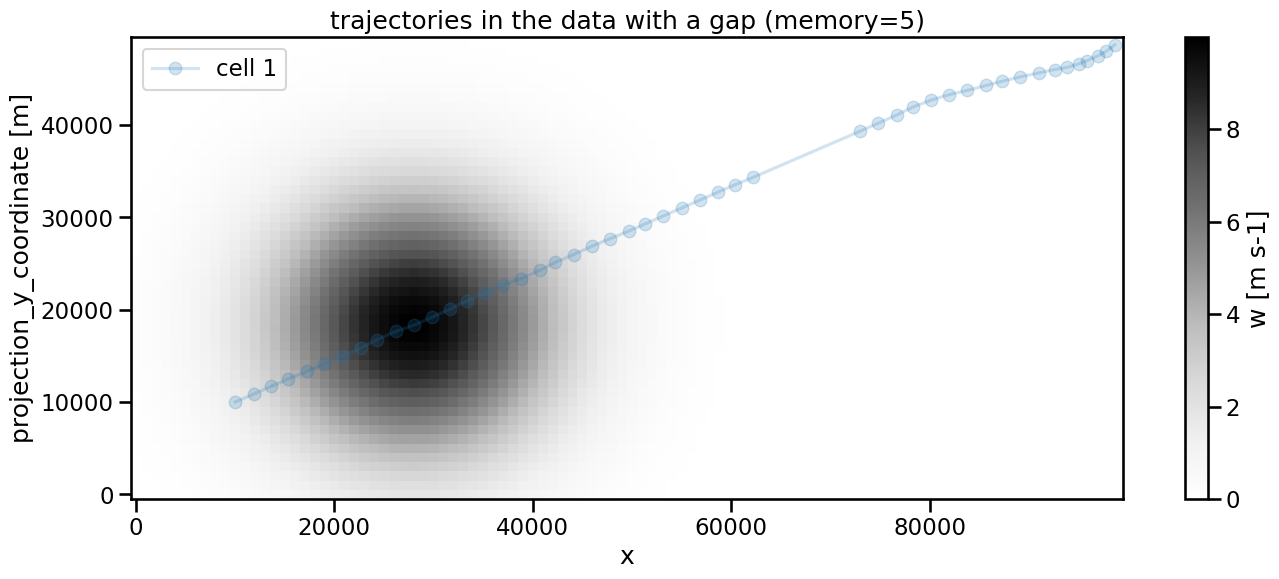

In [26]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(16, 6))

data_gap.isel(time=10).plot(ax=ax, x="x", y="y", cmap="Greys")

for i, cell_track in tracks_gap_mem.groupby("cell"):
    if i != -1:
        cell_track.plot(
            x="x",
            y="y",
            ax=ax,
            marker="o",
            alpha=0.2,
            label="cell {0}".format(int(i)),
        )

ax.set_title("trajectories in the data with a gap (memory=5)")
plt.legend()

## Timescale of the Tracks

If we want to limit our analysis to long living features of the dataset it is possible to exclude tracks which only cover few timesteps. This is done by setting a lower bound for those via the `stubs` parameter. In our 3-blob test data, only the first cell exceeds 50 time steps:

In [27]:
tracks_stubs = tobac.tracking.linking_overlap(features, labels, stubs=50)
np.unique(tracks_stubs.cell)

array([-1,  1])

Now, the DataFrame `tracks_stubs` contains two types (two categories) of cells:
1. *tracked cells*: connected with cell tracks
2. *untracked cells*: not connected

The first type (*"tracked cells"*) is what you know and what you have already worked with. But the 2nd type (*"untracked cells"*) is new. All untracked cells are marked with the cell index -1 and thus collected in a buffer space. Let's have a look:

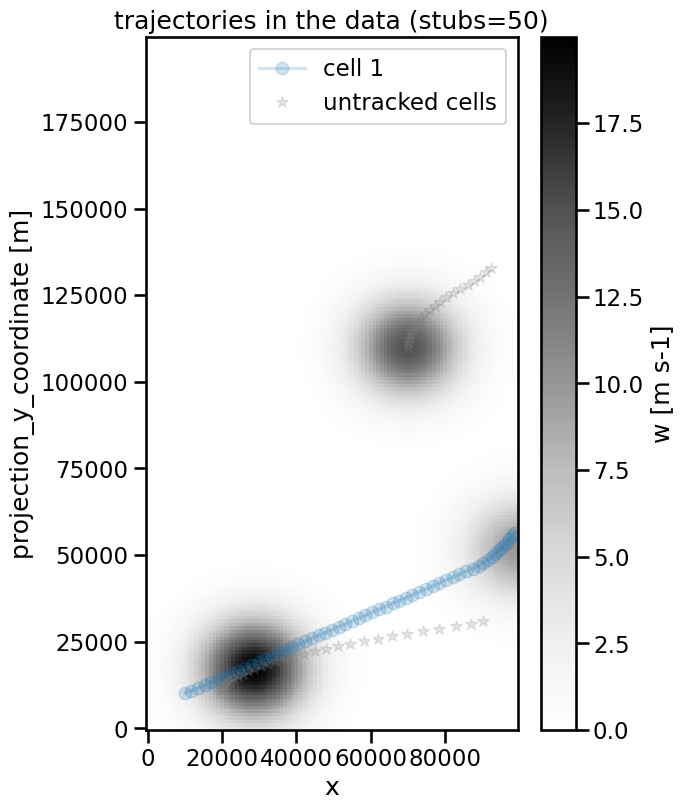

In [28]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6, 9))

data.isel(time=50).plot(ax=ax, x="x", y="y", cmap="Greys")

for i, cell_track in tracks_stubs.where(tracks_stubs.cell > 0).groupby("cell"):
    cell_track.plot(
        x="x",
        y="y",
        ax=ax,
        marker="o",
        alpha=0.2,
        label="cell {0}".format(int(i)),
    )

for i, cell_track in tracks_stubs.where(tracks_stubs.cell == -1).groupby("cell"):
    cell_track.plot(
        x="x",
        y="y",
        ax=ax,
        color="gray",
        marker="*",
        label="untracked cells",
        lw=0,
        alpha=0.2,
    )

ax.set_title("trajectories in the data (stubs=50)")
plt.legend()

## Periodic Boundary Conditions

For periodic domains (e.g. global data), the `PBC_flag` parameter (`'none'`, `'hdim_1'`, `'hdim_2'`, `'both'`) tells the tracking in which horizontal dimensions the domain wraps around: translated feature positions wrap at the domain edge, and overlaps are also computed across the boundary. We demonstrate this by rolling the 3-blob data by 50 grid cells in x, so that one of the blobs crosses the domain boundary. Note that feature detection needs to be run with the same `PBC_flag`:

In [29]:
%%capture

data_pbc = tobac.testing.make_sample_data_2D_3blobs(data_type="xarray").roll(x=50)
dxy, dt = 1000, 60
labels_pbc, features_pbc = tobac.feature_detection_multithreshold(
    data_pbc, dxy, threshold=5, position_threshold="weighted_abs", return_labels=True, PBC_flag="hdim_2"
)

In [30]:
tracks_pbc = tobac.tracking.linking_overlap(
    features_pbc, labels_pbc, minimum_relative_overlap=0.5,
    translate_method="predict", velocity_method="nearest", PBC_flag="hdim_2",
)
np.unique(tracks_pbc.cell)

array([1, 2, 3])

Without periodic boundary conditions, the blob crossing the domain boundary is split into several tracks instead:

In [31]:
tracks_no_pbc = tobac.tracking.linking_overlap(
    features_pbc, labels_pbc, minimum_relative_overlap=0.5,
    translate_method="predict", velocity_method="nearest", PBC_flag="none",
)
np.unique(tracks_no_pbc.cell)

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

## Tracking in 3D

Overlap tracking also works on 3D data: the mask then has an additional vertical dimension, the overlap is computed over voxels, and the vertical axis is detected automatically from the vertical coordinate (`vertical_coord` / `vertical_axis`). Here we use a 3D dataset with a single blob that is rolled across both horizontal boundaries, and pass the **segmentation mask** as the mask input:

In [32]:
%%capture

data_3d = tobac.testing.make_sample_data_3D_1blob(data_type="xarray").roll(y=25, x=50)
dxy, dt = tobac.utils.get_spacings(data_3d)
features_3d = tobac.feature_detection_multithreshold(
    data_3d, dxy, threshold=5, position_threshold="weighted_abs", PBC_flag="both"
)
labels_3d, features_3d = tobac.segmentation.segmentation(
    features_3d, data_3d, dxy, threshold=5, PBC_flag="both"
)

With `minimum_overlap=125` (i.e. at least 125 overlapping voxels required) and predictive linking, the single blob is tracked as one cell across the domain boundaries:

In [33]:
tracks_3d = tobac.tracking.linking_overlap(
    features_3d, labels_3d, minimum_overlap=125, translate_method="predict", velocity_method="mean", PBC_flag="both"
)
np.all(tracks_3d.cell == 1)

np.True_

## Other Parameters

The starting point of the cell index is arbitrary. If we want to change it from 1 to 0 we can do this with the `cell_number_start` parameter:

In [34]:
tracks_start0 = tobac.tracking.linking_overlap(features, labels, cell_number_start=0)
np.unique(tracks_start0.cell)

array([0, 1, 2])

Similarly, `cell_number_unassigned` sets the value used for features that are not part of any track (default -1). A full list of all parameters of `tobac.tracking.linking_overlap` and their descriptions can be found in the [API reference](https://tobac.readthedocs.io/en/latest/api/tobac.tracking.html) and the [overlap tracking user guide](https://tobac.readthedocs.io/en/latest/userguide/tracking/overlap_tracking.html).